# CalcFADC: TPC の FADC 波形から電荷を求める

TPC の各 FADC ch(アノード 12 ch、カソード 12 ch。1 ch = 32 ストリップの和)の波形から、
ベースラインを差し引いた電荷を求めます。SMILE_tool_box の `CalcFADC` と同じ手順です。

1. 最初の `base_window` サンプルの平均をベースラインとする
2. サンプル `Range_min` ≤ i < `Range_max` のうち、波形 − ベースライン > `threshold` のサンプルだけを足す
3. 該当サンプルがなければ電荷 = −100(ヒットなし)
4. `ADC_to_mV × Clock_to_nsec / 50` を掛けて単位を変換する

求めた電荷は `TPC_Calibration` が反跳電子のエネルギーに変換します。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `base_window` | 30 | ベースラインを求めるサンプル数 |
| `threshold` | 20 | 足し込むサンプルの閾値 [ADC] |
| `Range_min`, `Range_max` | 30, 500 | 積分するサンプル範囲 |
| `ADC_to_mV`, `Clock_to_nsec` | 2, 20 | 単位変換 |

In [1]:
import sys
from pathlib import Path
here = Path.cwd().resolve()
sys.path.insert(0, str(next(p for p in [here, *here.parents] if (p / "tutorial_utils.py").exists())))
import tutorial_utils as tu

import numpy as np
import matplotlib.pyplot as plt
ROOT = tu.setup_pyroot()

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

In [2]:
tu.print_download_instructions("Per02")
DATA_TOP = tu.check_data("Per02")

# 生データ(Per02)とパラメータを ~/smile2p_data にコピーする
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
data OK: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata  (Per02: 554 raw files)


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

In [3]:
# ReadData -> RawTreeWriter の出力(tutorials/cache/ に保存し、他のモジュールのノートブックと共有)
RAW = tu.get_raw("Per02", 5000)
INFO = tu.raw_info(RAW)
INFO

Per02_raw_5000.root は既にあるので再実行しません(overwrite=True で作り直し)


{'anode_ids': [1, 2, 3],
 'cathode_ids': [1, 2, 3],
 'ha_ids': [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]}

## 3. 生データツリーの波形から CalcFADC と同じ計算をする

下の関数は CalcFADC と同じ計算です(チェーン内の CalcFADC の値と完全に一致することを確認済み)。
パラメータを変えて、電荷がどう変わるかを試せます。

In [4]:
def calc_fadc(w, base_window=30, threshold=20., range_min=30, range_max=500, adc_to_mV=2., clock_to_nsec=20.):
    """w: [n_ch, 512] -> (baseline[n_ch], charge[n_ch])  (SMILE_tool_box CalcFADC)"""
    base = w[:, :base_window].sum(1) / base_window
    d = w[:, range_min:range_max] - base[:, None]
    over = d > threshold
    q = np.where(over.any(1), np.where(over, d, 0.).sum(1), -100.)
    return base, q * adc_to_mV * clock_to_nsec / 50.

rows = []   # (ch, baseline, charge with threshold 20, 10, 40)
for ch, w in tu.raw_waveforms(RAW):
    base, q20 = calc_fadc(w)
    _, q10 = calc_fadc(w, threshold=10.)
    _, q40 = calc_fadc(w, threshold=40.)
    rows.append(np.column_stack([ch, base, q20, q10, q40]))
r = np.concatenate(rows)
print(r.shape[0], "channel waveforms")

57744 channel waveforms


## 4. ベースラインと電荷

ch ごとのベースラインの分布と電荷の分布です(縦軸が ch 番号、0–11 アノード、12–23 カソード)。

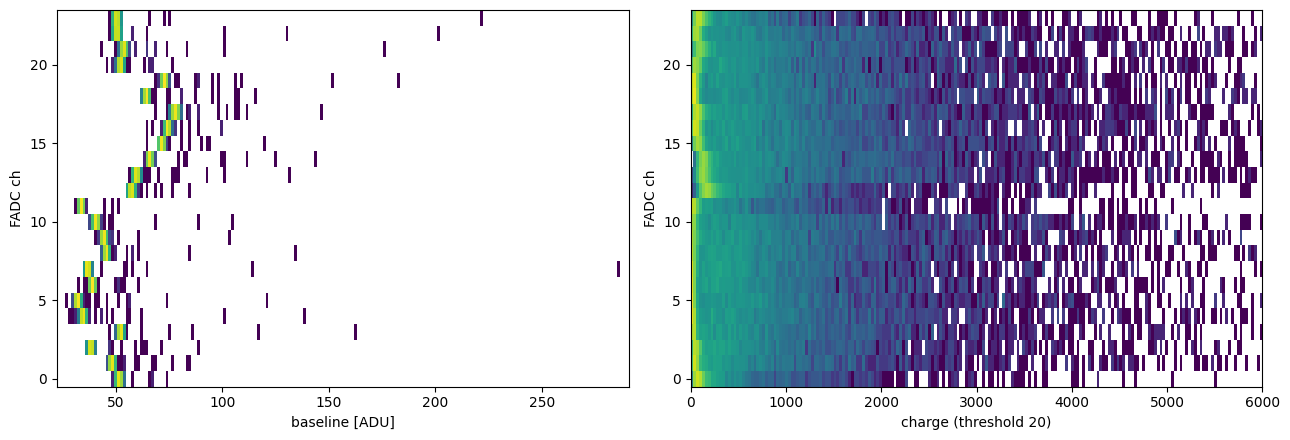

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist2d(r[:, 1], r[:, 0], bins=[200, 24], range=[[r[:, 1].min() - 5, r[:, 1].max() + 5], [-0.5, 23.5]], cmin=1, norm="log")
ax[0].set_xlabel("baseline [ADU]"); ax[0].set_ylabel("FADC ch")
ok = r[:, 2] > 0
ax[1].hist2d(r[ok, 2], r[ok, 0], bins=[200, 24], range=[[0, 6000], [-0.5, 23.5]], cmin=1, norm="log")
ax[1].set_xlabel("charge (threshold 20)"); ax[1].set_ylabel("FADC ch")
fig.tight_layout(); plt.show()

閾値を変えると電荷の分布がどう変わるか(全 ch):

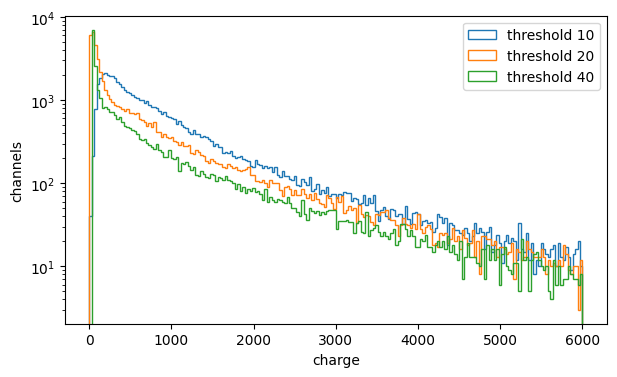

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for col, th in [(3, 10), (2, 20), (4, 40)]:
    q = r[:, col]; ax.hist(q[q > 0], bins=200, range=(0, 6000), histtype="step", label=f"threshold {th}")
ax.set_yscale("log"); ax.set_xlabel("charge"); ax.set_ylabel("channels"); ax.legend()
plt.show()